# Step 6: Predictive Churn Model
**Goal:** score every policy term with its probability of cancelling, so the retention team knows **which clients to contact first**.

Design choices:
- **No leakage:** only information known when the term starts is used. `Term_Status`, `Term_Expiration_Date` and the cancellation flags are excluded.
- **Out-of-time test:** train on terms starting in 2023, test on terms starting January to September 2024. Those terms have all reached renewal, so their outcome is known.
- **Two models:** logistic regression as an interpretable baseline, gradient boosting as the main model.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RAW, PROC, IMG = Path('../data/raw'), Path('../data/processed'), Path('../images')
IMG.mkdir(exist_ok=True); PROC.mkdir(parents=True, exist_ok=True)
pd.set_option('display.float_format', '{:,.2f}'.format)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False, 'axes.spines.right': False})
COLOR = '#2E6F95'

def save(fname):
    plt.tight_layout(); plt.savefig(IMG / fname, dpi=120); plt.show()

def load_raw():
    # EPIC_ID is built from client names: drop it on load so it never appears in any output
    terms = pd.read_excel(RAW / '1-insurance_2025_policy_terms.xlsx', sheet_name='result').drop(columns='EPIC_ID')
    demo = pd.read_excel(RAW / '2-insurance_2025_demographics.xlsx')
    return terms, demo
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score

## 6.1 Point-in-time features

In [2]:
df = pd.read_pickle(PROC / 'policy_terms_clean.pkl')
drivers = pd.read_pickle(PROC / 'auto_drivers_clean.pkl')[['Policy_Term_id', 'drivers', 'vehicles', 'years_licensed', 'liability_limit', 'youngest_driver_age', 'oldest_driver_age']]
df = df.merge(drivers, on='Policy_Term_id', how='left')

# client history known at the start of each term (other terms that started on or before it)
h = df[['Client_id', 'Policy_Term_id', 'Term_Effective_Date', 'LOB_Group']]
pairs = h.merge(h, on='Client_id', suffixes=('', '_o'))
pairs = pairs[(pairs['Policy_Term_id'] != pairs['Policy_Term_id_o']) & (pairs['Term_Effective_Date_o'] <= pairs['Term_Effective_Date'])]
pairs['other_group'] = pairs['LOB_Group_o'] != pairs['LOB_Group']
hist = pairs.groupby('Policy_Term_id').agg(other_terms_before=('Policy_Term_id_o', 'size'), bundled_at_start=('other_group', 'max'))
df = df.join(hist, on='Policy_Term_id')
df['other_terms_before'] = df['other_terms_before'].fillna(0)
df['bundled_at_start'] = df['bundled_at_start'].fillna(False).astype(int)
df['log_premium'] = np.log1p(df['Term_Premium'])
# renewal price change vs the previous term of the same policy (known when the renewal starts)
df = df.sort_values(['Policy_id', 'Term_Effective_Date'])
g = df.groupby('Policy_id')
df['terms_of_policy_before'] = g.cumcount()
df['premium_change'] = (df['Term_Premium'] / g['Term_Premium'].shift() - 1).clip(-1, 3)
for c in ['Line_of_Business', 'Province', 'Carrier_id']:
    df[c] = df[c].astype(str).astype('category')

CAT = ['Line_of_Business', 'Province', 'Carrier_id']
NUM = ['log_premium', 'premium_change', 'tenure_years', 'terms_of_policy_before', 'other_terms_before', 'bundled_at_start',
       'drivers', 'vehicles', 'youngest_driver_age']
FEATURES = CAT + NUM
assert not set(FEATURES) & {'Term_Status', 'Term_Expiration_Date', 'CAN_REN', 'CAN_MT', 'churned'}, 'leakage'
df[FEATURES].describe(include='all').T[['count', 'unique', 'mean']]

,count,unique,mean
Line_of_Business,99999,12,NaN
Province,99999,14,NaN
Carrier_id,99999,16,NaN
log_premium,"99,999.00",NaN,7.32
premium_change,"8,658.00",NaN,0.13
tenure_years,"99,999.00",NaN,3.53
terms_of_policy_before,"99,999.00",NaN,0.10
other_terms_before,"99,999.00",NaN,0.35
bundled_at_start,"99,999.00",NaN,0.18
drivers,"15,354.00",NaN,1.90


**Renewal price change is a strong churn signal.** It is only available for the 8.7% of terms that renew a policy already in the data, but the pattern is clear:

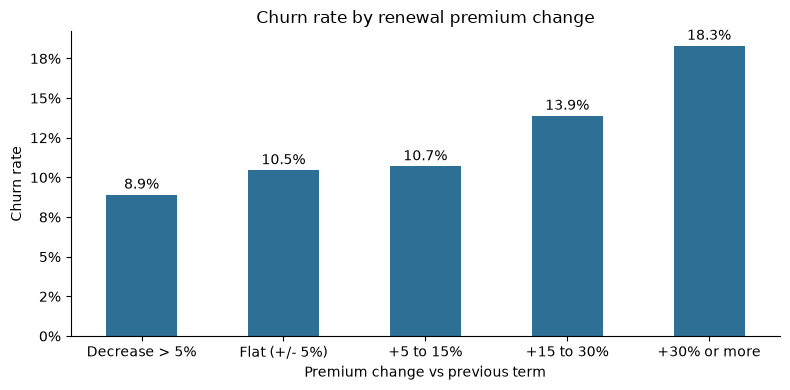

,terms,churn_rate
premium_change,,
Decrease > 5%,"1,134",8.9%
Flat (+/- 5%),"2,660",10.5%
+5 to 15%,"2,131",10.7%
+15 to 30%,"1,700",13.9%
+30% or more,"1,033",18.3%


In [3]:
r = df.dropna(subset=['premium_change'])
band = pd.cut(r['premium_change'], [-1, -0.05, 0.05, 0.15, 0.30, 3], labels=['Decrease > 5%', 'Flat (+/- 5%)', '+5 to 15%', '+15 to 30%', '+30% or more'])
chg = r.groupby(band, observed=True)['churned'].agg(terms='size', churn_rate='mean')
ax = chg['churn_rate'].plot.bar(color=COLOR, rot=0, title='Churn rate by renewal premium change')
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}'); ax.set_xlabel('Premium change vs previous term'); ax.set_ylabel('Churn rate')
ax.bar_label(ax.containers[0], labels=[f'{v:.1%}' for v in chg['churn_rate']], padding=2)
save('13_premium_change.png')
chg.style.format({'terms': '{:,.0f}', 'churn_rate': '{:.1%}'})

## 6.2 Out-of-time split

In [4]:
start = df['Term_Effective_Date']
train = df[start < '2024-01-01']
test = df[(start >= '2024-01-01') & (start < '2024-10-01')]
pd.DataFrame({'terms': [len(train), len(test)], 'churn_rate': [train.churned.mean(), test.churned.mean()]},
             index=['train (2023)', 'test (Jan-Sep 2024)']).style.format({'terms': '{:,.0f}', 'churn_rate': '{:.1%}'})

,terms,churn_rate
train (2023),"26,858",21.7%
test (Jan-Sep 2024),"33,527",22.2%


## 6.3 Train the models

In [5]:
logit = make_pipeline(
    ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50), CAT),
        ('num', make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler()), NUM),
    ]),
    LogisticRegression(max_iter=2000))
# shallow, regularised trees: deeper trees overfit 2023 patterns and scored worse on 2024
GBM_PARAMS = dict(categorical_features='from_dtype', max_depth=3, min_samples_leaf=200, learning_rate=0.05, max_iter=300, random_state=42)
gbm = HistGradientBoostingClassifier(**GBM_PARAMS)
models = {'Logistic regression': logit, 'Gradient boosting': gbm}
for m in models.values():
    m.fit(train[FEATURES], train['churned'])

## 6.4 Evaluate on the out-of-time test set
- **ROC AUC:** how well the model ranks churners above non-churners (0.5 = random).
- **Top 20% capture:** share of all actual cancellations found in the 20% of policies with the highest scores.

In [6]:
def capture(y, p, top=0.2):
    cut = np.quantile(p, 1 - top)
    return y[p >= cut].sum() / y.sum()

y = test['churned'].to_numpy()
scores = {name: m.predict_proba(test[FEATURES])[:, 1] for name, m in models.items()}
res = pd.DataFrame({name: {'ROC AUC': roc_auc_score(y, p), 'PR AUC': average_precision_score(y, p),
                           'Top 10% capture': capture(y, p, .1), 'Top 20% capture': capture(y, p, .2)}
                    for name, p in scores.items()}).T
res['Baseline (random) top 20%'] = 0.2
assert res.loc['Gradient boosting', 'ROC AUC'] > 0.6, 'model is barely better than random'
res.style.format('{:.3f}')

,ROC AUC,PR AUC,Top 10% capture,Top 20% capture,Baseline (random) top 20%
Logistic regression,0.618,0.291,0.142,0.293,0.200
Gradient boosting,0.658,0.326,0.169,0.344,0.200


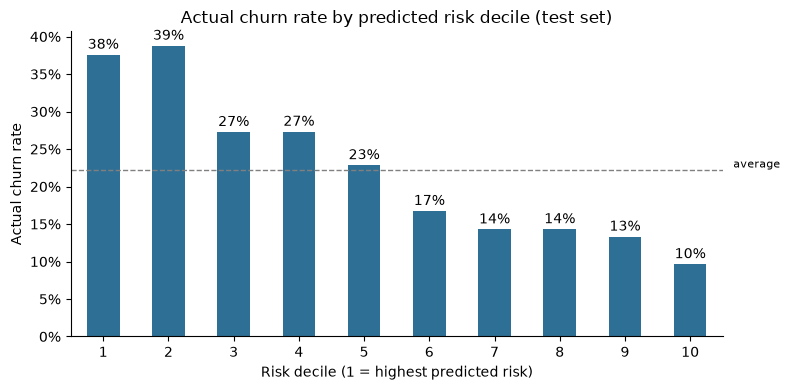

Top decile churns at 37.6%, 1.7x the average; bottom decile at 9.6%


In [7]:
p = scores['Gradient boosting']
test = test.assign(score=p, decile=pd.qcut(p, 10, labels=range(10, 0, -1)))
dec = test.groupby('decile', observed=True)['churned'].mean().sort_index(ascending=False)
ax = dec.plot.bar(color=COLOR, rot=0, title='Actual churn rate by predicted risk decile (test set)')
ax.axhline(test['churned'].mean(), color='grey', ls='--', lw=1); ax.text(9.6, test['churned'].mean(), ' average', va='bottom', fontsize=8)
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}'); ax.set_xlabel('Risk decile (1 = highest predicted risk)'); ax.set_ylabel('Actual churn rate')
ax.bar_label(ax.containers[0], labels=[f'{v:.0%}' for v in dec], padding=2)
save('11_model_deciles.png')
print(f'Top decile churns at {dec.iloc[0]:.1%}, {dec.iloc[0] / test.churned.mean():.1f}x the average; bottom decile at {dec.iloc[-1]:.1%}')

## 6.5 What drives the predictions?
Permutation importance: how much the test ROC AUC drops when a feature is shuffled.

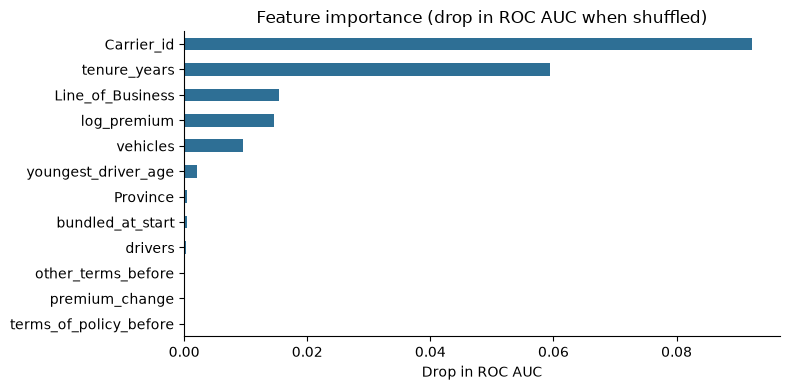

,importance
Carrier_id,0.09
tenure_years,0.06
Line_of_Business,0.02
log_premium,0.01
vehicles,0.01
youngest_driver_age,0.00
Province,0.00
bundled_at_start,0.00
drivers,0.00
other_terms_before,0.00


In [8]:
imp = permutation_importance(gbm, test[FEATURES], y, scoring='roc_auc', n_repeats=5, random_state=42)
imp = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
ax = imp.plot.barh(color=COLOR, title='Feature importance (drop in ROC AUC when shuffled)')
ax.set_xlabel('Drop in ROC AUC')
save('12_feature_importance.png')
imp.sort_values(ascending=False).round(4).to_frame('importance')

## 6.6 Risk tiers
Cut-offs come from the test set: **High** = top 20% of scores, **Medium** = next 30%, **Low** = bottom 50%.

In [9]:
hi, mid = np.quantile(p, [0.8, 0.5])
tier = lambda s: np.select([s >= hi, s >= mid], ['High', 'Medium'], 'Low')
test['risk_tier'] = tier(p)
tiers = test.groupby('risk_tier').agg(terms=('churned', 'size'), churn_rate=('churned', 'mean'), cancellations=('churned', 'sum'))
tiers['share_of_cancellations'] = tiers['cancellations'] / tiers['cancellations'].sum()
tiers.loc[['High', 'Medium', 'Low']].style.format({'terms': '{:,.0f}', 'churn_rate': '{:.1%}', 'cancellations': '{:,.0f}', 'share_of_cancellations': '{:.1%}'})

,terms,churn_rate,cancellations,share_of_cancellations
risk_tier,,,,
High,"6,706",38.2%,"2,559",34.4%
Medium,"10,149",25.7%,"2,604",35.0%
Low,"16,672",13.6%,"2,272",30.6%


## 6.7 Score the current book
The final model is retrained on all terms with a known outcome (2023 to September 2024) and scores every term. Scores feed the Power BI dashboard.

In [10]:
known = df[df['Term_Effective_Date'] < '2024-10-01']
final = HistGradientBoostingClassifier(**GBM_PARAMS).fit(known[FEATURES], known['churned'])
df['risk_score'] = final.predict_proba(df[FEATURES])[:, 1]
df['risk_tier'] = tier(df['risk_score'])

active = df[(df['start_year'] == 2025) & df['Term_Status'].isin(['NEW', 'REN', 'REI'])]
print(f'Active 2025 terms: {len(active):,}')
active.groupby('risk_tier').agg(terms=('risk_score', 'size'), avg_score=('risk_score', 'mean'),
                                premium=('Term_Premium', 'sum')).loc[['High', 'Medium', 'Low']].style.format(
    {'terms': '{:,.0f}', 'avg_score': '{:.1%}', 'premium': '${:,.0f}'})

Active 2025 terms: 26,492


,terms,avg_score,premium
risk_tier,,,
High,"4,258",34.8%,"$10,831,606"
Medium,"11,053",19.7%,"$24,108,918"
Low,"11,181",11.6%,"$18,905,493"


In [11]:
# who is in the High tier? links the model back to the recommendations
h = active[active['risk_tier'] == 'High']
pd.DataFrame({
    'Carrier 65575 in AB or NB': ((h['Carrier_id'] == '65575') & h['Province'].isin(['AB', 'NB'])).mean(),
    'Single-line auto, tenure <= 5 yrs': ((h['LOB_Group'] == 'Auto') & (h['bundled_at_start'] == 0) & (h['tenure_years'] <= 5)).mean(),
    'Top premium quartile': (h['premium_quartile'] == 'Q4 (highest)').mean(),
    'Tenant or rented dwelling': h['Line_of_Business'].isin(['TPAC', 'RDWL']).mean(),
}, index=['share of High-risk active terms']).T.style.format('{:.1%}')

,share of High-risk active terms
Carrier 65575 in AB or NB,6.9%
"Single-line auto, tenure <= 5 yrs",45.5%
Top premium quartile,46.3%
Tenant or rented dwelling,22.5%


## 6.8 Summary

**Model performance (out-of-time test, January to September 2024)**
- Gradient boosting reaches a ROC AUC of **0.66**, ahead of the logistic regression baseline (0.62).
- The **High** risk tier (top 20% of scores) churns at **38%**, against 14% for the Low tier, and holds **34% of all cancellations**. Random targeting of 20% of clients would find only 20%.
- The top decile churns at about 1.7 times the average rate.

**What drives risk:** carrier, customer tenure and line of business matter most, followed by premium and vehicle count. This matches the descriptive analysis in Step 4.

**Renewal price change is a strong signal:** a premium increase of 30% or more comes with 18.3% churn, against 10.5% when the premium stays flat. It is available for few terms, so it adds little to the model today, but it supports the renewal price alert recommendation.

**How the business can use it**
- Score each policy about 60 days before renewal and give the **High** tier to the retention team first: about 4,300 active 2025 terms holding $10.8M in premium.
- Almost half of the High tier are single-line auto clients in their first five years and top-quartile premium policies, so the model turns recommendations 2 and 3 into a ranked call list.

**Why the AUC is moderate:** the data has no claims history, service contacts, competitor quotes or full renewal price history, which usually drive cancellation. Adding these is the clearest way to improve the model. A ROC AUC around 0.65 is still useful for ranking, as the tier results show, but it should not be used to make decisions about individual clients without human review.


## 6.9 Export for the Power BI dashboard
One flat table with the cleaned fields, engineered segments and risk scores. Identifiers are kept only as numeric keys; no names, birth dates or postal codes.

In [12]:
tenure_order = {'<1 yr': 1, '1-3 yrs': 2, '3-5 yrs': 3, '5-10 yrs': 4, '10+ yrs': 5}
LOB_NAMES = {'AUTO': 'Auto', 'HOME': 'Home', 'TPAC': 'Tenant package', 'CNDO': 'Condo', 'TRAI': 'Trailer',
             'RDWL': 'Rented dwelling', 'MOTO': 'Motorcycle', 'BOAT': 'Boat', 'SDWL': 'Seasonal dwelling',
             'RCON': 'Rented condo', 'MHOM': 'Motorhome', 'RVEH': 'Recreational vehicle'}
out = pd.DataFrame({
    'Policy_Term_id': df['Policy_Term_id'], 'Client_id': df['Client_id'],
    'Carrier': 'Carrier ' + df['Carrier_id'].astype(str), 'Province': df['Province'].astype(str),
    'Line_of_Business': df['Line_of_Business'].astype(str), 'LOB_Group': df['LOB_Group'], 'Bundled': df['bundled'],
    # small groups give unstable rates, so charts use these grouped versions (same thresholds as Step 4)
    'Province_Group': df['Province'].astype(str).where(df.groupby('Province', observed=True)['Province'].transform('size') >= 1000, 'Other'),
    'LOB_Display': df['Line_of_Business'].astype(str).where(df.groupby('Line_of_Business', observed=True)['Line_of_Business'].transform('size') >= 200, 'Other'),
    'LOB_Name': df['Line_of_Business'].astype(str).map(LOB_NAMES).where(df.groupby('Line_of_Business', observed=True)['Line_of_Business'].transform('size') >= 200, 'Other'),
    'Carrier_Group': ('Carrier ' + df['Carrier_id'].astype(str)).where(df.groupby('Carrier_id', observed=True)['Carrier_id'].transform('size') >= 1000, 'Other carriers'),
    'Tenure_Band': df['tenure_band'].astype(str), 'Tenure_Order': df['tenure_band'].astype(str).map(tenure_order),
    'Premium_Quartile': df['premium_quartile'].astype(str), 'Term_Start': df['Term_Effective_Date'].dt.date,
    'Start_Year': df['start_year'], 'Term_Premium': df['Term_Premium'].round(2), 'Premium_Outlier': df['premium_outlier'].astype(int),
    'CAN_REN': df['CAN_REN'], 'CAN_MT': df['CAN_MT'], 'Churned': df['churned'],
    'Risk_Score': df['risk_score'].round(4), 'Risk_Tier': df['risk_tier'],
    'Risk_Tier_Order': df['risk_tier'].map({'High': 1, 'Medium': 2, 'Low': 3}),
    # tier from the 2023-only model, so the dashboard's model check uses out-of-time scores
    'Test_Risk_Tier': df['Policy_Term_id'].map(test.set_index('Policy_Term_id')['risk_tier']).fillna('Not in test'),
    'Is_Active_2025': ((df['start_year'] == 2025) & df['Term_Status'].isin(['NEW', 'REN', 'REI'])).astype(int),
    'Priority_Segment': ((df['LOB_Group'] == 'Auto') & (df['bundled'] == 'Single line') & (df['tenure_years'] <= 5)).astype(int),
})
assert out['Policy_Term_id'].is_unique and out.notna().all().all()
out.shape

(99999, 27)

### Anonymised copy for the shareable Power BI file
The published Power BI file embeds its data, so it uses a further anonymised copy: IDs are replaced with random numbers,
start dates are kept only to the month, premiums are rounded to the nearest $10 and rows are shuffled.
Every rate on the dashboard stays the same.

In [13]:
rng = np.random.default_rng(42)
pub = out.sample(frac=1, random_state=42).reset_index(drop=True)
pub['Policy_Term_id'] = rng.permutation(len(pub)) + 1
clients = pub['Client_id'].unique()
pub['Client_id'] = pub['Client_id'].map(pd.Series(rng.permutation(len(clients)) + 1, index=clients))
pub['Term_Start'] = pd.to_datetime(pub['Term_Start']).dt.to_period('M').dt.to_timestamp().dt.date
pub['Term_Premium'] = pub['Term_Premium'].round(-1)

# self-check: same rows, same rates, no original IDs left
assert len(pub) == len(out) and pub['Client_id'].nunique() == out['Client_id'].nunique()
assert pub['Churned'].mean() == out['Churned'].mean()
assert not pub['Policy_Term_id'].isin(out['Policy_Term_id']).all()
PUB = Path('../data/powerbi_public'); PUB.mkdir(parents=True, exist_ok=True)
pub.to_csv(PUB / 'policy_terms.csv', index=False)
print(pub.shape, '->', PUB / 'policy_terms.csv')

(99999, 27) -> ..\data\powerbi_public\policy_terms.csv
